In [35]:
import pandas as pd

train = pd.read_csv("../data/processed/model_train.csv")
test = pd.read_csv("../data/processed/model_test.csv")

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("\nTraining data:")
display(train.head())

Training shape: (1204, 11)
Testing shape: (302, 11)

Training data:


,SEQN,RIDAGEYR,female,INDFMPIR,LBXGH,BMXBMI,BPXOSY1,BPXODI1,smoking,insulin,kidney_marker
0,113730.0,80.0,0,0.77,6.2,24.2,133.0,72.0,never,0.0,1.0
1,121183.0,70.0,0,3.33,7.7,26.2,149.0,74.0,never,1.0,1.0
2,124142.0,53.0,1,5.00,7.3,29.1,126.0,85.0,never,0.0,0.0
3,112421.0,65.0,0,5.00,5.8,25.8,112.0,75.0,former,0.0,0.0
4,117019.0,71.0,0,NaN,6.8,37.6,175.0,98.0,former,0.0,0.0


**Check missing values and data types**

In [36]:
print("Missing values in training data:")
print(train.isnull().sum())

print("\nData types:")
print(train.dtypes)

print("\nSmoking categories:")
print(train["smoking"].value_counts(dropna=False))

print("\nInsulin values:")
print(train["insulin"].value_counts(dropna=False))

Missing values in training data:
SEQN               0
RIDAGEYR           0
female             0
INDFMPIR         163
LBXGH             17
BMXBMI            26
BPXOSY1          126
BPXODI1          126
smoking            0
insulin          217
kidney_marker      0
dtype: int64

Data types:
SEQN             float64
RIDAGEYR         float64
female             int64
INDFMPIR         float64
LBXGH            float64
BMXBMI           float64
BPXOSY1          float64
BPXODI1          float64
smoking              str
insulin          float64
kidney_marker    float64
dtype: object

Smoking categories:
smoking
never      638
former     379
current    185
unknown      2
Name: count, dtype: int64

Insulin values:
insulin
0.0    698
1.0    289
NaN    217
Name: count, dtype: int64


Define training and testing features

In [37]:
target = "kidney_marker"

numeric_features = [
    "RIDAGEYR", "INDFMPIR", "LBXGH",
    "BMXBMI", "BPXOSY1", "BPXODI1"
]

binary_features = ["female", "insulin"]
categorical_features = ["smoking"]

X_train = train.drop(columns=["SEQN", target])
y_train = train[target].astype(int)

X_test = test.drop(columns=["SEQN", target])
y_test = test[target].astype(int)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (1204, 9)
Testing features: (302, 9)


**Data Preprocessing Pipeline**

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent",
                              add_indicator=True))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("binary", binary_pipeline, binary_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


Fit and transform the datasets

In [39]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("Missing values in training:", pd.isna(X_train_processed).sum())
print("Missing values in testing:", pd.isna(X_test_processed).sum())

Processed training shape: (1204, 13)
Processed testing shape: (302, 13)
Missing values in training: 0
Missing values in testing: 0


**Import the machine learning models**

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss"
    )
}

print("Three machine learning models initialized successfully.")

Three machine learning models initialized successfully.


**5-fold cross-validation**

In [41]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, confusion_matrix

def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return tn / (tn + fp)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "specificity": make_scorer(specificity_score),
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": name}

    for metric in scoring:
        result[metric] = scores["test_" + metric].mean()

    cv_results.append(result)

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,Logistic Regression,0.6661,0.6407,0.5250,0.7735,0.5756,0.7162,0.6741
1,Random Forest,0.6478,0.5989,0.5654,0.7106,0.5801,0.6933,0.6292
2,XGBoost,0.6503,0.6109,0.5269,0.7442,0.5649,0.6829,0.6156


###  Cross-Validation Results and Comparison

The three machine learning models were evaluated using stratified 5-fold cross-validation. Logistic Regression achieved the highest accuracy (66.61%), precision (64.07%), specificity (77.35%), ROC-AUC (0.7162), and PR-AUC (0.6741). Random Forest obtained the highest recall (56.54%) and F1-score (0.5801), indicating a better balance between precision and recall. XGBoost showed comparatively lower performance across most evaluation metrics.

Overall, Logistic Regression demonstrated the strongest discrimination performance, while Random Forest showed slightly better sensitivity. Further hyperparameter optimization and evaluation on the independent test dataset are required before selecting the final model.

### Hyperparameter tuning for all three models

In [42]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Define all three pipelines
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Parameter combinations
parameters = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 5, 10, 15],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__class_weight": [None, "balanced"]
    },
    "XGBoost": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [2, 3, 4, 5],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__subsample": [0.7, 0.9, 1.0],
        "classifier__colsample_bytree": [0.7, 0.9, 1.0]
    }
}

pipelines = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

# Tune all three models
tuned_models = {}

for name, pipeline in pipelines.items():

    print("Tuning:", name)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    tuned_models[name] = search

print("\nAll three models tuned successfully.")

Tuning: Logistic Regression
Tuning: Random Forest
Tuning: XGBoost

All three models tuned successfully.


Best Parameters and ROC-AUC Comparison

In [43]:
tuning_results = []

for name, search in tuned_models.items():

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "Best CV ROC-AUC": round(search.best_score_, 4)
    })

tuning_results_df = pd.DataFrame(tuning_results)

display(tuning_results_df)

,Model,Best Parameters,Best CV ROC-AUC
0,Logistic Regression,"{'classifier__class_weight': None, 'classifier...",0.7165
1,Random Forest,"{'classifier__n_estimators': 200, 'classifier_...",0.7087
2,XGBoost,"{'classifier__subsample': 0.7, 'classifier__n_...",0.7099


**Final Model Evaluation on Test Data**

In [44]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

test_results = []

for name, search in tuned_models.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6556,0.6174,0.5420,0.7427,0.5772,0.7123,0.6697
1,Random Forest,0.6325,0.5735,0.5954,0.6608,0.5843,0.7037,0.6622
2,XGBoost,0.6556,0.6364,0.4809,0.7895,0.5478,0.7197,0.6964


**Confusion Matrices**

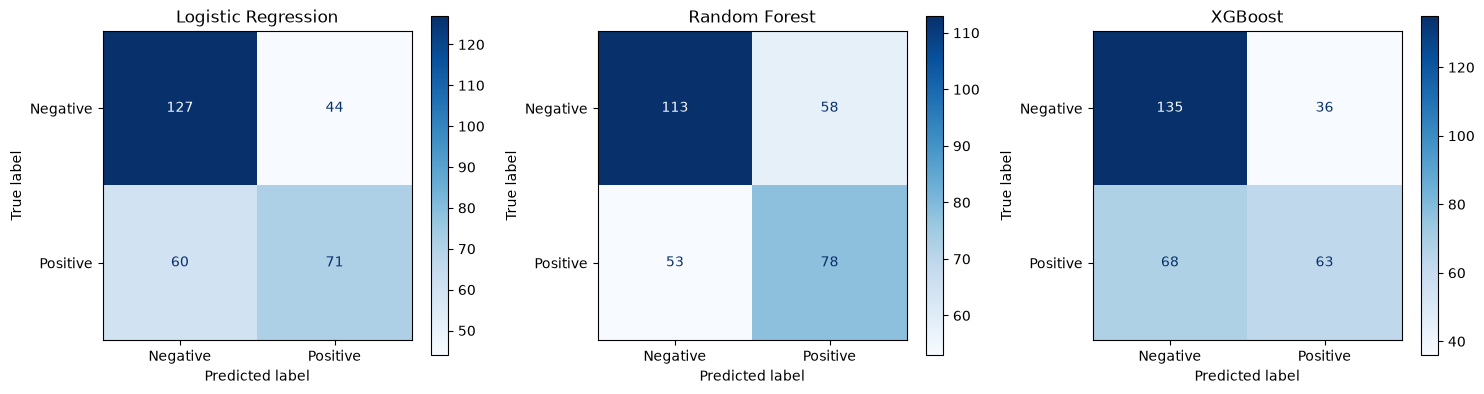

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, search) in zip(axes, tuned_models.items()):

    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

 **ROC and Precision-Recall Curve Analysis**

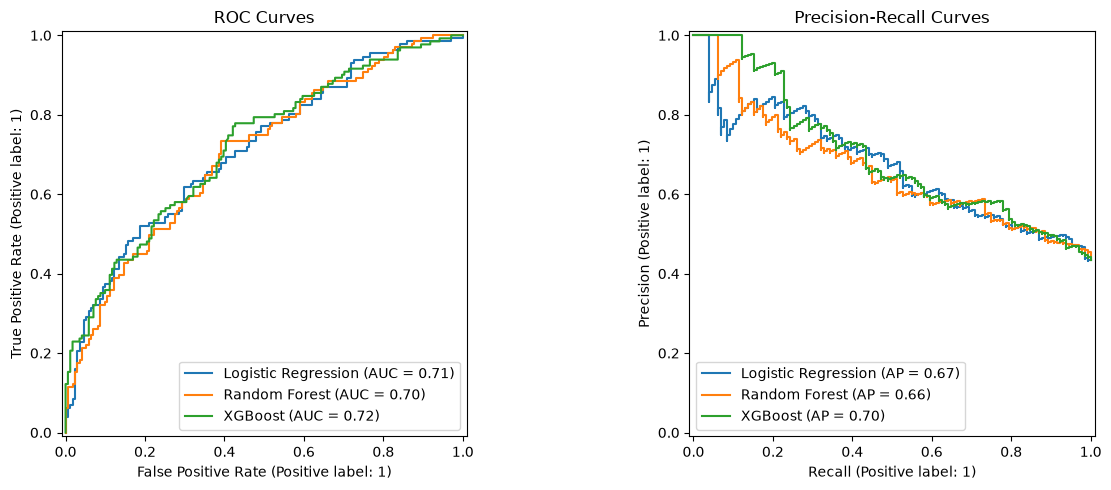

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, search in tuned_models.items():
    best_model = search.best_estimator_

    RocCurveDisplay.from_estimator(
        best_model, X_test, y_test, ax=axes[0], name=name
    )

    PrecisionRecallDisplay.from_estimator(
        best_model, X_test, y_test, ax=axes[1], name=name
    )

axes[0].set_title("ROC Curves")
axes[1].set_title("Precision-Recall Curves")

plt.tight_layout()
plt.show()

**SHAP Explainability Analysis**

In [47]:
import shap
print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


**SHAP Feature Importance Analysis**

In [48]:
# Select the trained Random Forest model
rf_model = tuned_models["Random Forest"].best_estimator_

# Transform the training data
X_train_transformed = rf_model.named_steps["preprocessor"].transform(X_train)

# Create SHAP explainer
explainer = shap.TreeExplainer(
    rf_model.named_steps["classifier"]
)

# Calculate SHAP values
shap_values = explainer.shap_values(X_train_transformed)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


**SHAP Summary Plot**

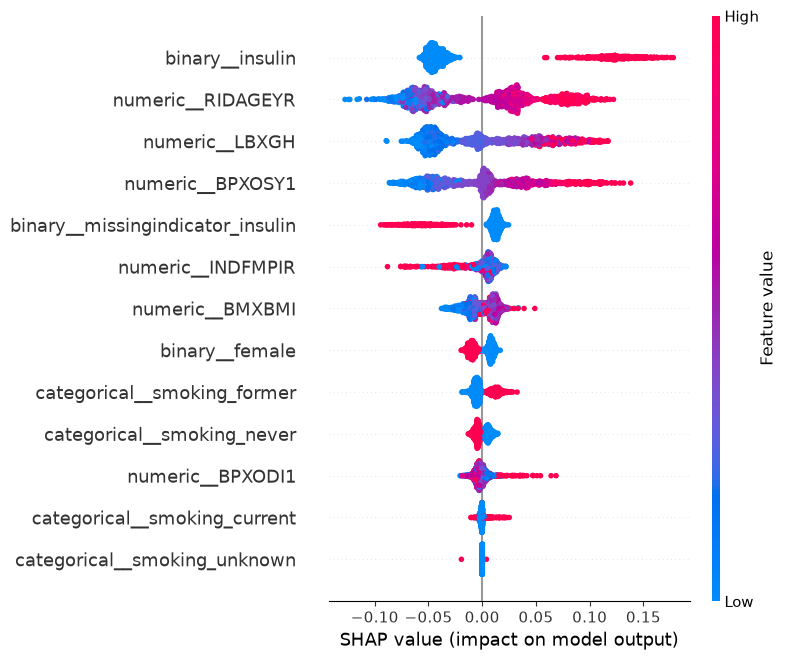

In [49]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_train_transformed,
    feature_names=rf_model.named_steps["preprocessor"].get_feature_names_out()
)

**Individual SHAP Explanation**

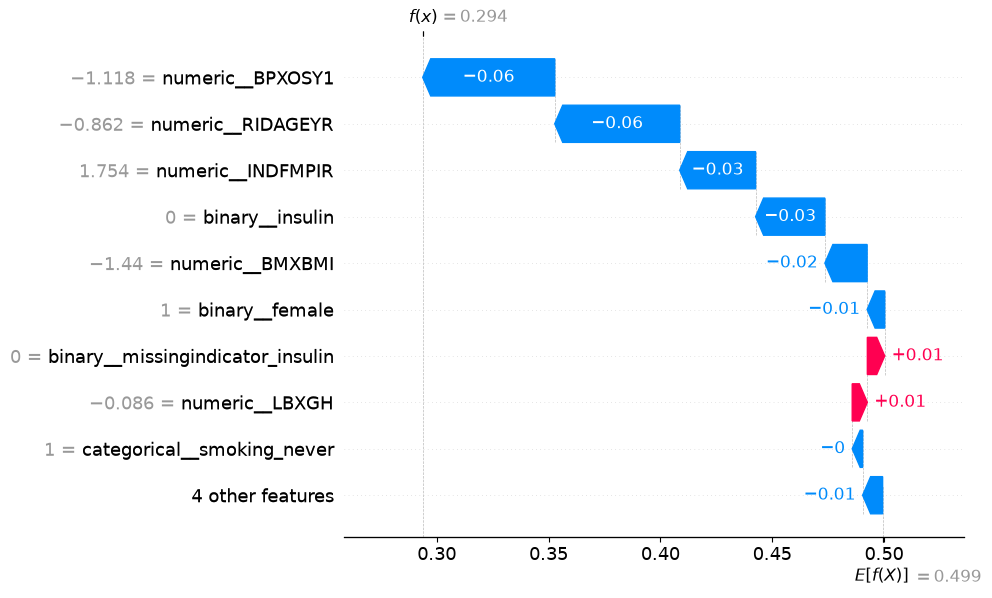

In [50]:

X_test_transformed = rf_model.named_steps["preprocessor"].transform(X_test)


test_shap_values = explainer.shap_values(X_test_transformed)

# Display individual explanation
shap.waterfall_plot(
    shap.Explanation(
        values=test_shap_values[0, :, 1],
        base_values=explainer.expected_value[1],
        data=X_test_transformed[0],
        feature_names=rf_model.named_steps["preprocessor"].get_feature_names_out()
    )
)

**Feature Importance Ranking**

In [51]:
import pandas as pd
import numpy as np

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importance_values = np.mean(
    np.abs(shap_values[:, :, 1]),
    axis=0
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP Value": importance_values
})

feature_importance = feature_importance.sort_values(
    by="Mean Absolute SHAP Value",
    ascending=False
).reset_index(drop=True)

feature_importance.index = feature_importance.index + 1

display(feature_importance.round(4))

,Feature,Mean Absolute SHAP Value
1,binary__insulin,0.0627
2,numeric__RIDAGEYR,0.0509
3,numeric__LBXGH,0.0443
4,numeric__BPXOSY1,0.0372
5,binary__missingindicator_insulin,0.0206
6,numeric__INDFMPIR,0.0113
7,numeric__BMXBMI,0.0110
8,binary__female,0.0088
9,categorical__smoking_former,0.0079
10,categorical__smoking_never,0.0052


**Sensitivity Analysis**

Prepare data without HbA1c

In [52]:
# Remove HbA1c from training and testing data
X_train_no_hba1c = X_train.drop(columns=["LBXGH"])
X_test_no_hba1c = X_test.drop(columns=["LBXGH"])

# Update numerical features
numeric_features_no_hba1c = [
    feature for feature in numeric_features
    if feature != "LBXGH"
]

# Create updated preprocessing pipeline
preprocessor_no_hba1c = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features_no_hba1c),
    ("binary", binary_pipeline, binary_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training shape:", X_train_no_hba1c.shape)
print("Testing shape:", X_test_no_hba1c.shape)
print("HbA1c removed successfully.")

Training shape: (1204, 8)
Testing shape: (302, 8)
HbA1c removed successfully.


Train and tune the models without HbA1c

In [53]:
from sklearn.model_selection import RandomizedSearchCV

pipelines_no_hba1c = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor_no_hba1c),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_no_hba1c),
        ("classifier", RandomForestClassifier(random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor_no_hba1c),
        ("classifier", XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ))
    ])
}

tuned_models_no_hba1c = {}

for name, pipeline in pipelines_no_hba1c.items():
    print("Training:", name)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train_no_hba1c, y_train)
    tuned_models_no_hba1c[name] = search

print("\nAll models trained successfully without HbA1c.")

Training: Logistic Regression
Training: Random Forest
Training: XGBoost

All models trained successfully without HbA1c.


Evaluate models without HbA1c

In [54]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

results_no_hba1c = []

for name, search in tuned_models_no_hba1c.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test_no_hba1c)
    y_prob = best_model.predict_proba(X_test_no_hba1c)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results_no_hba1c.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_no_hba1c_df = pd.DataFrame(results_no_hba1c)

display(results_no_hba1c_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6623,0.6330,0.5267,0.7661,0.5750,0.7061,0.6817
1,Random Forest,0.6523,0.6000,0.5954,0.6959,0.5977,0.6918,0.6664
2,XGBoost,0.6854,0.7432,0.4198,0.8889,0.5366,0.7101,0.6793


Sensitivity Analysis – Without Insulin

In [55]:
# Remove insulin from training and testing data
X_train_no_insulin = X_train.drop(columns=["insulin"])
X_test_no_insulin = X_test.drop(columns=["insulin"])

# Update binary features
binary_features_no_insulin = ["female"]

# Create updated preprocessing pipeline
preprocessor_no_insulin = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("binary", binary_pipeline, binary_features_no_insulin),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training shape:", X_train_no_insulin.shape)
print("Testing shape:", X_test_no_insulin.shape)
print("Insulin removed successfully.")

Training shape: (1204, 8)
Testing shape: (302, 8)
Insulin removed successfully.


Train and tune models without insulin

In [56]:
pipelines_no_insulin = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor_no_insulin),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_no_insulin),
        ("classifier", RandomForestClassifier(random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor_no_insulin),
        ("classifier", XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ))
    ])
}

tuned_models_no_insulin = {}

for name, pipeline in pipelines_no_insulin.items():
    print("Training:", name)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train_no_insulin, y_train)
    tuned_models_no_insulin[name] = search

print("\nAll models trained successfully without insulin.")

Training: Logistic Regression
Training: Random Forest
Training: XGBoost

All models trained successfully without insulin.


Evaluate models without insulin

In [57]:
results_no_insulin = []

for name, search in tuned_models_no_insulin.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test_no_insulin)
    y_prob = best_model.predict_proba(X_test_no_insulin)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results_no_insulin.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_no_insulin_df = pd.DataFrame(results_no_insulin)

display(results_no_insulin_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6788,0.6545,0.5496,0.7778,0.5975,0.7194,0.6666
1,Random Forest,0.6589,0.5909,0.6947,0.6316,0.6386,0.7133,0.6567
2,XGBoost,0.6656,0.6389,0.5267,0.7719,0.5774,0.7160,0.6854


Sensitivity Analysis – Replacing BMI with Waist Circumference

In [58]:
preprocessor_waist = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features_waist),
    ("binary", binary_pipeline, binary_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Waist circumference preprocessing pipeline created.")

Waist circumference preprocessing pipeline created.


In [59]:
X_train_waist = train_waist.drop(
    columns=["SEQN", "kidney_marker", "BMXBMI"]
)

X_test_waist = test_waist.drop(
    columns=["SEQN", "kidney_marker", "BMXBMI"]
)

print("Training shape:", X_train_waist.shape)
print("Testing shape:", X_test_waist.shape)

Training shape: (1204, 9)
Testing shape: (302, 9)


Train and Tune Models Using Waist Circumference

In [60]:
tuned_models_waist = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor_waist),
        ("classifier", model)
    ])

    search = RandomizedSearchCV(
        pipeline,
        parameters[name],
        n_iter=10,
        scoring="roc_auc",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    print("Training:", name)

    search.fit(X_train_waist, y_train)

    tuned_models_waist[name] = search

    print("Best CV ROC-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)
    print("-" * 50)

Training: Logistic Regression
Best CV ROC-AUC: 0.7145
Best parameters: {'classifier__class_weight': None, 'classifier__C': 0.1}
--------------------------------------------------
Training: Random Forest
Best CV ROC-AUC: 0.7104
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced'}
--------------------------------------------------
Training: XGBoost
Best CV ROC-AUC: 0.7123
Best parameters: {'classifier__subsample': 0.7, 'classifier__n_estimators': 100, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.9}
--------------------------------------------------


Evaluate Models on Test Data

In [61]:
results_waist = []

for name, search in tuned_models_waist.items():

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test_waist)
    y_prob = best_model.predict_proba(X_test_waist)[:, 1]

    results_waist.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": recall_score(y_test, y_pred, pos_label=0),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_waist_df = pd.DataFrame(results_waist)

display(results_waist_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.6854,0.6607,0.5649,0.7778,0.6091,0.7202,0.6757
1,Random Forest,0.6358,0.5827,0.5649,0.6901,0.5736,0.7091,0.6767
2,XGBoost,0.6623,0.6436,0.4962,0.7895,0.5603,0.7206,0.6958


Compare All Sensitivity Analyses

In [63]:


original = test_results_df.copy()
original["Experiment"] = "Original"

no_hba1c = results_no_hba1c_df.copy()
no_hba1c["Experiment"] = "Without HbA1c"

no_insulin = results_no_insulin_df.copy()
no_insulin["Experiment"] = "Without Insulin"

waist = results_waist_df.copy()
waist["Experiment"] = "BMI Replaced with Waist"

# Combine results
sensitivity_comparison = pd.concat(
    [original, no_hba1c, no_insulin, waist],
    ignore_index=True
)

# Calculate missing F1 scores
sensitivity_comparison["F1"] = (
    2 * sensitivity_comparison["Precision"] *
    sensitivity_comparison["Recall"]
) / (
    sensitivity_comparison["Precision"] +
    sensitivity_comparison["Recall"]
)

# Display comparison table
display(
    sensitivity_comparison[
        ["Experiment", "Model", "Accuracy", "Precision",
         "Recall", "Specificity", "F1", "ROC-AUC", "PR-AUC"]
    ].round(4)
)

,Experiment,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC
0,Original,Logistic Regression,0.6556,0.6174,0.5420,0.7427,0.5772,0.7123,0.6697
1,Original,Random Forest,0.6325,0.5735,0.5954,0.6608,0.5843,0.7037,0.6622
2,Original,XGBoost,0.6556,0.6364,0.4809,0.7895,0.5478,0.7197,0.6964
3,Without HbA1c,Logistic Regression,0.6623,0.6330,0.5267,0.7661,0.5750,0.7061,0.6817
4,Without HbA1c,Random Forest,0.6523,0.6000,0.5954,0.6959,0.5977,0.6918,0.6664
5,Without HbA1c,XGBoost,0.6854,0.7432,0.4198,0.8889,0.5366,0.7101,0.6793
6,Without Insulin,Logistic Regression,0.6788,0.6545,0.5496,0.7778,0.5975,0.7194,0.6666
7,Without Insulin,Random Forest,0.6589,0.5909,0.6947,0.6316,0.6386,0.7133,0.6567
8,Without Insulin,XGBoost,0.6656,0.6389,0.5267,0.7719,0.5774,0.7160,0.6854
9,BMI Replaced with Waist,Logistic Regression,0.6854,0.6607,0.5649,0.7778,0.6091,0.7202,0.6757
